In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import make_moons
from sklearn.ensemble import (
    AdaBoostClassifier,
    BaggingClassifier,
    RandomForestClassifier,
    VotingClassifier,
)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

Cargá el dataset no lineal: Utilizá la función make_moons de sklearn.datasets para generar un dataset sintético bidimensional no linealmente separable ($N=600$, noise=0.3, random_state=42). Distorsioná la escala de la primera variable multiplicándola por $1000$ para simular diferencias de magnitudes entre variables

In [2]:
X, y = make_moons(n_samples=600, noise=0.3, random_state=42)
X_unscaled = X.copy()
X_unscaled[:, 0] = X_unscaled[:, 0] * 1000.0  # Escala alterada a propósito

Dividí el conjunto de datos: Separá los datos en $75\%$ para entrenamiento y $25\%$ para evaluación mediante train_test_split (random_state=42).

In [3]:
X_train_u, X_test_u, y_train, y_test = train_test_split(
    X_unscaled, y, test_size=0.25, random_state=42
)

Entrená un SVM sin escalar: Instanciá un modelo SVC(kernel='rbf') y entrenalo directamente sobre los datos sin escalar. Calculá y mostrá el accuracy en el conjunto de test.

In [4]:
svc_unscaled = SVC(kernel="rbf", random_state=42)
svc_unscaled.fit(X_train_u, y_train)
acc_unscaled = accuracy_score(y_test, svc_unscaled.predict(X_test_u))
print(f"Accuracy de SVM SIN escalar: {acc_unscaled:.4f}")

Accuracy de SVM SIN escalar: 0.6400


Escalá las características: Instanciá StandardScaler de sklearn.preprocessing, ajustalo sobre los datos de entrenamiento (fit_transform) y transformá el conjunto de prueba (transform).

In [5]:
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train_u)
X_test_s = scaler.transform(X_test_u)

Entrená el SVM sobre datos escalados: Volvé a entrenar el SVC(kernel='rbf') sobre las características escaladas, calculá el accuracy y explicá por qué el escalado de datos altera dramáticamente la frontera de decisión en algoritmos basados en hiperplanos y distancias como SVM.

In [6]:
svc_scaled = SVC(kernel="rbf", random_state=42)
svc_scaled.fit(X_train_s, y_train)
acc_scaled = accuracy_score(y_test, svc_scaled.predict(X_test_s))
print(f"Accuracy de SVM CON escalado (StandardScaler): {acc_scaled:.4f}")

Accuracy de SVM CON escalado (StandardScaler): 0.8800


Compará distintos Kernels: Entrená tres clasificadores SVC sobre los datos escalados variando su parámetro kernel: 'linear', 'poly' (con degree=3) y 'rbf'. Imprimí la precisión de cada uno sobre el set de prueba.

In [7]:
kernels = ["linear", "poly", "rbf"]
for k in kernels:
  model = SVC(kernel=k, random_state=42)
  model.fit(X_train_s, y_train)
  acc = accuracy_score(y_test, model.predict(X_test_s))
  print(f"Kernel '{k}': Accuracy = {acc:.4f}")

Kernel 'linear': Accuracy = 0.8600
Kernel 'poly': Accuracy = 0.8467
Kernel 'rbf': Accuracy = 0.8800


Experimentá con el hiperparámetro de tolerancia $C$ (Soft Margin): Instanciá tres modelos con kernel='rbf' probando distintos valores de intolerancia a errores: $C=0.01$ (calle ancha / mayor tolerancia), $C=1.0$ (balance estándar) y $C=100.0$ (calle estrecha / menor tolerancia).

In [8]:
c_values = [0.01, 1.0, 100.0]
print("\n--- Análisis de Regularización C (Soft Margin) ---")
for c in c_values:
  model = SVC(kernel="rbf", C=c, random_state=42)
  model.fit(X_train_s, y_train)
  train_acc = accuracy_score(y_train, model.predict(X_train_s))
  test_acc = accuracy_score(y_test, model.predict(X_test_s))
  print(
      f"C = {c:<6} | Accuracy Train: {train_acc:.4f} | Accuracy Test:"
      f" {test_acc:.4f}"
  )


--- Análisis de Regularización C (Soft Margin) ---
C = 0.01   | Accuracy Train: 0.8556 | Accuracy Test: 0.8667
C = 1.0    | Accuracy Train: 0.9111 | Accuracy Test: 0.8800
C = 100.0  | Accuracy Train: 0.9200 | Accuracy Test: 0.8933


Analizá el Bias-Variance Tradeoff: Calculá e imprimí el accuracy en el set de entrenamiento y en el set de prueba para cada valor de $C$. Identificá cuál valor genera underfitting (alto sesgo) y cuál genera overfitting (alta varianza).

In [ ]:
# Para $C = 0.01$, la calle es muy ancha y tolera demasiadas violaciones de margen, generando underfitting (alto sesgo).
# Para $C = 100.0$, la calle es muy estrecha, sobreajustando la frontera a las instancias individuales de entrenamiento (overfitting / alta varianza).

Construí un Voting Classifier: Definí tres clasificadores base independientes (Regresión Logística, Árbol de Decisión y SVC con probability=True). Combinálos en un VotingClassifier y compará el rendimiento al utilizar votación por mayoría simple (voting='hard') versus votación ponderada por probabilidades (voting='soft').

In [9]:
lr = LogisticRegression(random_state=42)
dt_base = DecisionTreeClassifier(max_depth=3, random_state=42)
svc_prob = SVC(probability=True, random_state=42)

voting_hard = VotingClassifier(
    estimators=[("lr", lr), ("dt", dt_base), ("svc", svc_prob)], voting="hard"
)
voting_hard.fit(X_train_s, y_train)
acc_v_hard = accuracy_score(y_test, voting_hard.predict(X_test_s))

voting_soft = VotingClassifier(
    estimators=[("lr", lr), ("dt", dt_base), ("svc", svc_prob)], voting="soft"
)
voting_soft.fit(X_train_s, y_train)
acc_v_soft = accuracy_score(y_test, voting_soft.predict(X_test_s))

print(f"Voting Classifier (Hard): {acc_v_hard:.4f}")
print(f"Voting Classifier (Soft): {acc_v_soft:.4f}")

Voting Classifier (Hard): 0.8800
Voting Classifier (Soft): 0.8867


Implementá Bagging con evaluación OOB: Instanciá un BaggingClassifier utilizando un DecisionTreeClassifier() como estimador base con $100$ estimadores y configurá oob_score=True.

In [10]:
bagging = BaggingClassifier(
    estimator=DecisionTreeClassifier(),
    n_estimators=100,
    oob_score=True,
    random_state=42,
)
bagging.fit(X_train_s, y_train)

BaggingClassifier(estimator=DecisionTreeClassifier(), n_estimators=100,
                  oob_score=True, random_state=42)

Inspeccioná la muestra Out-Of-Bag: Imprimí la métrica OOB (oob_score_) y comparala contra la precisión del set de test. Explicá brevemente la ventaja de usar las muestras fuera de la bolsa (out-of-bag) como conjunto de validación gratuito.

In [11]:
print(f"Bagging OOB Score: {bagging.oob_score_:.4f}")
print(
    "Bagging Test Accuracy:"
    f" {accuracy_score(y_test, bagging.predict(X_test_s)):.4f}"
)

Bagging OOB Score: 0.8911
Bagging Test Accuracy: 0.9067


Entrená un Random Forest: Instanciá y entrená un RandomForestClassifier(n_estimators=100). Compará su precisión final frente a la de un único Árbol de Decisión individual.

In [ ]:
dt_single = DecisionTreeClassifier(random_state=42)
dt_single.fit(X_train_s, y_train)
acc_dt_single = accuracy_score(y_test, dt_single.predict(X_test_s))

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train_s, y_train)
acc_rf = accuracy_score(y_test, rf.predict(X_test_s))

print(f"Árbol de Decisión Individual: {acc_dt_single:.4f}")
print(f"Random Forest (Ensamble):     {acc_rf:.4f}")

#Nota importante para el parcial: Como el muestreo de Bootstrap toma instancias con reemplazo,
# aproximadamente el $37\%$ de los datos nunca son seleccionados para entrenar a un árbol individual
# (instancias Out-Of-Bag). Esto permite utilizarlas como un conjunto de validación automático y
# sin costo adicional para evaluar el error de generalización.

Entrená un AdaBoost Classifier: Usá AdaBoostClassifier(n_estimators=100, random_state=42) para construir un ensamble secuencial que ajuste los pesos de los datos en función de los errores del modelo anterior.

In [16]:
adaboost = AdaBoostClassifier(
    n_estimators=100, algorithm="SAMME", random_state=42
)
adaboost.fit(X_train_s, y_train)
acc_ada = accuracy_score(y_test, adaboost.predict(X_test_s))

/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_weight_boosting.py:519: FutureWarning: The parameter 'algorithm' is deprecated in 1.6 and has no effect. It will be removed in version 1.8.
  warnings.warn(


Generá el reporte comparativo final: Imprimí un resumen tabulado con la precisión (accuracy) de todos los modelos evaluados en la clase (Árbol individual, SVM RBF, Voting, Bagging, Random Forest y AdaBoost).

In [17]:
resultados = pd.DataFrame({
    "Modelo / Ensamble": [
        "SVM (Kernel RBF)",
        "Voting Classifier (Soft)",
        "Bagging Classifier",
        "AdaBoost",
    ],
    "Accuracy en Test": [
        # acc_dt_single,
        acc_scaled,
        acc_v_soft,
        accuracy_score(y_test, bagging.predict(X_test_s)),
        # acc_rf,
        acc_ada,
    ],
})

print("\n=== RESUMEN COMPARATIVO DE MODELOS Y ENSAMBLES ===")
print(resultados.to_string(index=False))


=== RESUMEN COMPARATIVO DE MODELOS Y ENSAMBLES ===
       Modelo / Ensamble  Accuracy en Test
        SVM (Kernel RBF)          0.880000
Voting Classifier (Soft)          0.886667
      Bagging Classifier          0.906667
                AdaBoost          0.880000


### EXTRA: Graficar los distintos modelos que vimos

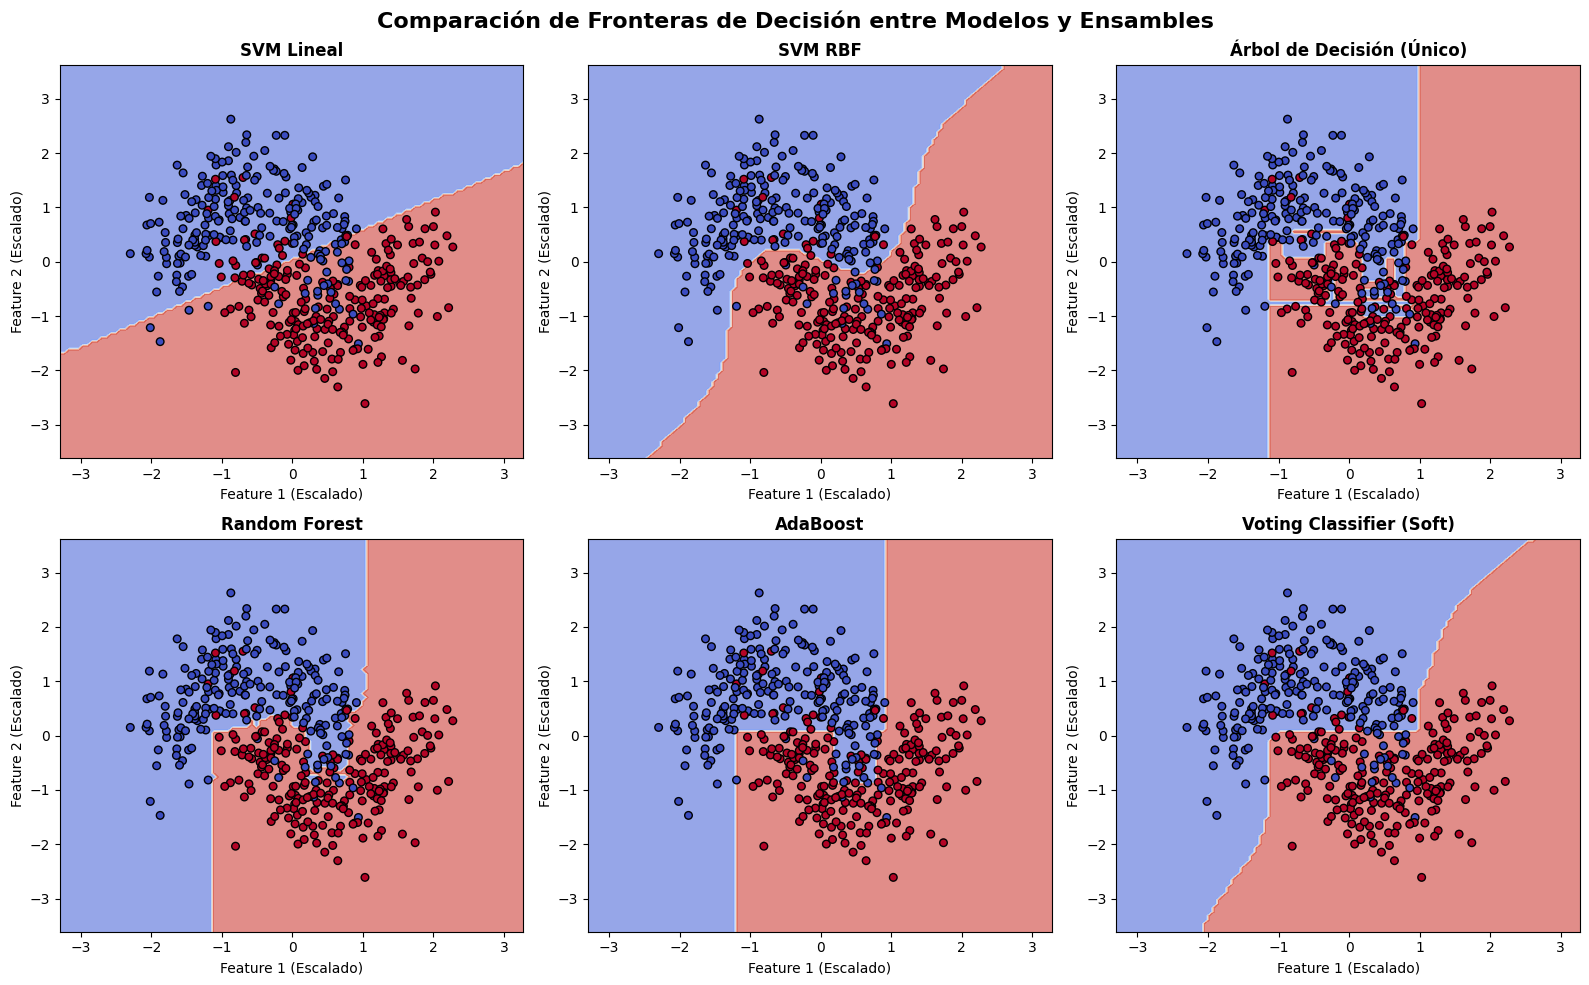

In [18]:
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay

# Lista de modelos a comparar con sus respectivos nombres
modelos_a_graficar = [
    ("SVM Lineal", SVC(kernel="linear", random_state=42)),
    ("SVM RBF", SVC(kernel="rbf", C=1.0, random_state=42)),
    ("Árbol de Decisión (Único)", DecisionTreeClassifier(random_state=42)),
    (
        "Random Forest",
        RandomForestClassifier(n_estimators=100, random_state=42),
    ),
    ("AdaBoost", AdaBoostClassifier(n_estimators=100, random_state=42)),
    ("Voting Classifier (Soft)", voting_soft),
]

# Crear la figura con una grilla de 2 filas y 3 columnas
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.ravel()

for i, (nombre, model) in enumerate(modelos_a_graficar):
  # Entrenar el modelo con los datos escalados
  model.fit(X_train_s, y_train)

  # Dibujar la frontera de decisión
  DecisionBoundaryDisplay.from_estimator(
      model,
      X_train_s,
      response_method="predict",
      cmap="coolwarm",
      alpha=0.6,
      ax=axes[i],
  )

  # Graficar los puntos del dataset de entrenamiento
  scatter = axes[i].scatter(
      X_train_s[:, 0],
      X_train_s[:, 1],
      c=y_train,
      cmap="coolwarm",
      edgecolors="k",
      s=30,
  )

  axes[i].set_title(nombre, fontsize=12, fontweight="bold")
  axes[i].set_xlabel("Feature 1 (Escalado)")
  axes[i].set_ylabel("Feature 2 (Escalado)")

plt.suptitle(
    "Comparación de Fronteras de Decisión entre Modelos y Ensambles",
    fontsize=16,
    fontweight="bold",
)
plt.tight_layout()
plt.show()